# Paddy Dataset Machine Learning Project

# 0. Introduction

Paddy Dataset

* UCI Machine Learning Repository

* Donated on 7/14/2025

Agriculture occupies a third of Earth's surface and is vital for food production. Rice, grown from paddy seeds, feeds nearly half the global population.

To support efficient agricultural production and meet rising food demands, this project applies Machine Learning techniques to analyze the factors associated with paddy productivity and predict paddy yield.

The main objective of this project is to develop regression models for predicting Paddy Yield based on agricultural and environmental features. We first conduct exploratory data analysis to examine the distributions and relationships between the features and the target variable. We then apply Principal Component Analysis to reduce the dimensionality of the feature space and investigate whether a lower-dimensional representation can improved prediction performance. Finally, we compare Linear Regression, Lasso Regression, Random Forest, and Support Vector Regression models.

# Table of Contents

0. [Introduction](#0-introduction)

1. [Data Understanding](#1-data-understanding)
   - [1.1 Data Loading](#11-loading-data)
   - [1.2 Data Information](#12-data-information)

2. [Exploratory Data Analysis](#2-exploratory-data-analysis)
   - [2.1 Target Variable](#21-target-variable)
   - [2.2 Numerical Features](#22-numerical-features)
   - [2.3 Categorical Features](#22-categorical-features)
   - [2.4 EDA Summary](#23-eda-summary)

3. [Dimensionality Reduction](#3-dimensionality-reduction)
   - [3.1 Data Preprocessing](#31-data-preprocessing)
   - [3.2 Principal Component Analysis (PCA)](#32-principal-component-analysis-pca)

4. [Paddy Yield Prediction](#4-paddy-yield-prediction)
   - [4.1 Linear Regression](#41-linear-regression)
   - [4.2 Lasso Regression](#42-lasso-regression)
   - [4.3 Support Vector Regression](#43-support-vector-regression)
   - [4.4 Model Comparison](#44-model-comparison)

5. [Concluding Remarks](#5-concluding-remarks)

6. [References](#6-references)

# 1. Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1.1 Data Loading

In [2]:
# read the paddy dataset
path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/paddy_dataset.csv'
data = pd.read_csv(path, na_values=['NA', 'Nan', 'N/A', 'na', 'n/a', 'null', 'NULL', 'None', 'none', ''])

# print(f"{data.columns}")
print(f"{data.shape}")
data.head()

(2789, 45)


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [3]:
# information of columns
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   object 
 2   Variety                             2789 non-null   object 
 3   Soil Types                          2789 non-null   object 
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   object 
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                         2789 no

In [4]:
# Check the missing values
print("Missing values in each column:")
print(data.isnull().sum())

Missing values in each column:
Hectares                              0
Agriblock                             0
Variety                               0
Soil Types                            0
Seedrate(in Kg)                       0
LP_Mainfield(in Tonnes)               0
Nursery                               0
Nursery area (Cents)                  0
LP_nurseryarea(in Tonnes)             0
DAP_20days                            0
Weed28D_thiobencarb                   0
Urea_40Days                           0
Potassh_50Days                        0
Micronutrients_70Days                 0
Pest_60Day(in ml)                     0
30DRain( in mm)                       0
30DAI(in mm)                          0
30_50DRain( in mm)                    0
30_50DAI(in mm)                       0
51_70DRain(in mm)                     0
51_70AI(in mm)                        0
71_105DRain(in mm)                    0
71_105DAI(in mm)                      0
Min temp_D1_D30                       0
Max temp_

## 1.2 Data Information

* **Instances:** 2,789
* **Features:** 44
* **Target:** Paddy yield
* **Task:** Regression
* **Missing Values:** None

| Variable                               | Role       | Type        | Description                                                    | Units    | Missing Values |
| -------------------------------------- | ---------- | ----------- | -------------------------------------------------------------- | -------- | -------------- |
| **Hectares**                           | Feature    | Integer     | Cultivated land area                                           | hectares | No             |
| **Agriblock**                          | Feature    | Categorical | Agricultural block                                             | —        | No             |
| **Variety**                            | Feature    | Categorical | Paddy variety                                                  | —        | No             |
| **Soil Types**                         | Feature    | Categorical | Soil type                                                      | —        | No             |
| **Seedrate(in Kg)**                    | Feature    | Integer     | Quantity of seed used                                          | kg       | No             |
| **LP_Mainfield(in Tonnes)**            | Feature    | Continuous  | Main-field input/production measure                            | tonnes   | No             |
| **Nursery**                            | Feature    | Categorical | Nursery-related category                                       | —        | No             |
| **Nursery area (Cents)**               | Feature    | Integer     | Nursery area                                                   | cents    | No             |
| **LP_nurseryarea(in Tonnes)**          | Feature    | Integer     | Nursery-area input/production measure                          | tonnes   | No             |
| **DAP_20days**                         | Feature    | Integer     | DAP application at 20 days                                     | —        | No             |
| **Weed28D_thiobencarb**                | Feature    | Integer     | Thiobencarb application for weed control at 28 days            | —        | No             |
| **Urea_40Days**                        | Feature    | Continuous  | Urea application at 40 days                                    | —        | No             |
| **Potassh_50Days**                     | Feature    | Continuous  | Potash application at 50 days                                  | —        | No             |
| **Micronutrients_70Days**              | Feature    | Integer     | Micronutrient application at 70 days                           | —        | No             |
| **Pest_60Day(in ml)**                  | Feature    | Integer     | Pest-control application at 60 days                            | ml       | No             |
| **30DRain(in mm)**                     | Feature    | Continuous  | Rainfall during the first 30 days                              | mm       | No             |
| **30DAI(in mm)**                       | Feature    | Continuous  | Agricultural irrigation/water measure during the first 30 days | mm       | No             |
| **30_50DRain(in mm)**                  | Feature    | Continuous  | Rainfall during days 30–50                                     | mm       | No             |
| **30_50DAI(in mm)**                    | Feature    | Continuous  | Agricultural irrigation/water measure during days 30–50        | mm       | No             |
| **51_70DRain(in mm)**                  | Feature    | Continuous  | Rainfall during days 51–70                                     | mm       | No             |
| **51_70AI(in mm)**                     | Feature    | Continuous  | Agricultural irrigation/water measure during days 51–70        | mm       | No             |
| **71_105DRain(in mm)**                 | Feature    | Continuous  | Rainfall during days 71–105                                    | mm       | No             |
| **71_105DAI(in mm)**                   | Feature    | Continuous  | Agricultural irrigation/water measure during days 71–105       | mm       | No             |
| **Min temp_D1_D30**                    | Feature    | Continuous  | Minimum temperature during days 1–30                           | —        | No             |
| **Max temp_D1_D30**                    | Feature    | Integer     | Maximum temperature during days 1–30                           | —        | No             |
| **Min temp_D31_D60**                   | Feature    | Continuous  | Minimum temperature during days 31–60                          | —        | No             |
| **Max temp_D31_D60**                   | Feature    | Integer     | Maximum temperature during days 31–60                          | —        | No             |
| **Min temp_D61_D90**                   | Feature    | Integer     | Minimum temperature during days 61–90                          | —        | No             |
| **Max temp_D61_D90**                   | Feature    | Integer     | Maximum temperature during days 61–90                          | —        | No             |
| **Min temp_D91_D120**                  | Feature    | Continuous  | Minimum temperature during days 91–120                         | —        | No             |
| **Max temp_D91_D120**                  | Feature    | Integer     | Maximum temperature during days 91–120                         | —        | No             |
| **Inst Wind Speed_D1_D30(in Knots)**   | Feature    | Integer     | Instantaneous wind speed during days 1–30                      | knots    | No             |
| **Inst Wind Speed_D31_D60(in Knots)**  | Feature    | Integer     | Instantaneous wind speed during days 31–60                     | knots    | No             |
| **Inst Wind Speed_D61_D90(in Knots)**  | Feature    | Integer     | Instantaneous wind speed during days 61–90                     | knots    | No             |
| **Inst Wind Speed_D91_D120(in Knots)** | Feature    | Integer     | Instantaneous wind speed during days 91–120                    | knots    | No             |
| **Wind Direction_D1_D30**              | Feature    | Categorical | Wind direction during days 1–30                                | —        | No             |
| **Wind Direction_D31_D60**             | Feature    | Categorical | Wind direction during days 31–60                               | —        | No             |
| **Wind Direction_D61_D90**             | Feature    | Categorical | Wind direction during days 61–90                               | —        | No             |
| **Wind Direction_D91_D120**            | Feature    | Categorical | Wind direction during days 91–120                              | —        | No             |
| **Relative Humidity_D1_D30**           | Feature    | Continuous  | Relative humidity during days 1–30                             | —        | No             |
| **Relative Humidity_D31_D60**          | Feature    | Integer     | Relative humidity during days 31–60                            | —        | No             |
| **Relative Humidity_D61_D90**          | Feature    | Integer     | Relative humidity during days 61–90                            | —        | No             |
| **Relative Humidity_D91_D120**         | Feature    | Integer     | Relative humidity during days 91–120                           | —        | No             |
| **Trash(in bundles)**                  | Feature    | Integer     | Amount of trash                                                | bundles  | No             |
| **Paddy yield(in Kg)**                 | **Target** | Integer     | Paddy yield                                                    | kg       | No             |



# 2. Exploratory Data Analysis

## 2.1 Target Variable

In [5]:
# Group features by data type

categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
integer_features = data.select_dtypes(include=['int64']).columns.tolist()
continuous_features = data.select_dtypes(include=['float64']).columns.tolist()
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist() # integer + continuous

# separate the target
target = 'Paddy yield(in Kg)'
integer_features = [col for col in integer_features if col != target]

print(f"Categorical features ({len(categorical_features)}):")
print(categorical_features)
print(f"\nInteger features ({len(integer_features)}):")
print(integer_features)
print(f"\nContinuous features ({len(continuous_features)}):")
print(continuous_features)
print(f"\nTarget:")
print(target)

Categorical features (8):
['Agriblock', 'Variety', 'Soil Types', 'Nursery', 'Wind Direction_D1_D30', 'Wind Direction_D31_D60', 'Wind Direction_D61_D90', 'Wind Direction_D91_D120']

Integer features (18):
['Hectares ', 'Seedrate(in Kg)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days', 'Weed28D_thiobencarb', 'Micronutrients_70Days', 'Pest_60Day(in ml)', 'Max temp_D1_D30', 'Max temp_D31_D60', 'Inst Wind Speed_D1_D30(in Knots)', 'Inst Wind Speed_D31_D60(in Knots)', 'Inst Wind Speed_D61_D90(in Knots)', 'Inst Wind Speed_D91_D120(in Knots)', 'Relative Humidity_D31_D60', 'Relative Humidity_D61_D90', 'Relative Humidity_D91_D120', 'Trash(in bundles)']

Continuous features (18):
['LP_Mainfield(in Tonnes)', 'Urea_40Days', 'Potassh_50Days', '30DRain( in mm)', '30DAI(in mm)', '30_50DRain( in mm)', '30_50DAI(in mm)', '51_70DRain(in mm)', '51_70AI(in mm)', '71_105DRain(in mm)', '71_105DAI(in mm)', 'Min temp_D1_D30', 'Min temp_D31_D60', 'Min temp_D61_D90', 'Max temp_D61_D90', 'Min te

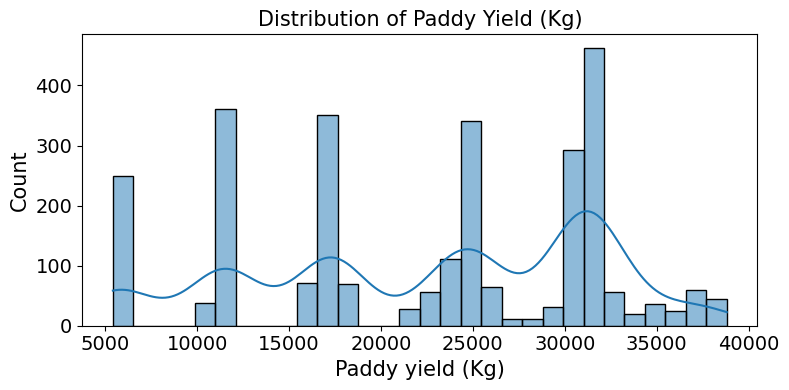

In [8]:
# Target distribution
plt.figure(figsize=(8,4))
sns.histplot(data['Paddy yield(in Kg)'], kde=True, bins=30)
plt.title('Distribution of Paddy Yield (Kg)', fontsize=15)
plt.xlabel('Paddy yield (Kg)', fontsize=15)
plt.ylabel('Count', fontsize=15)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Distribution_of_Paddy_Yield.png', dpi=300, bbox_inches='tight')
plt.show()

The target distribution has a wave-like pattern, it goes up and down and up and down.

This could indicate:

* multiple groups/subpopulations in the data,
* some categorical variable separating the observations,
* different agricultural conditions,
* or simply the way the observations were collected.



## 2.2 Numerical Features

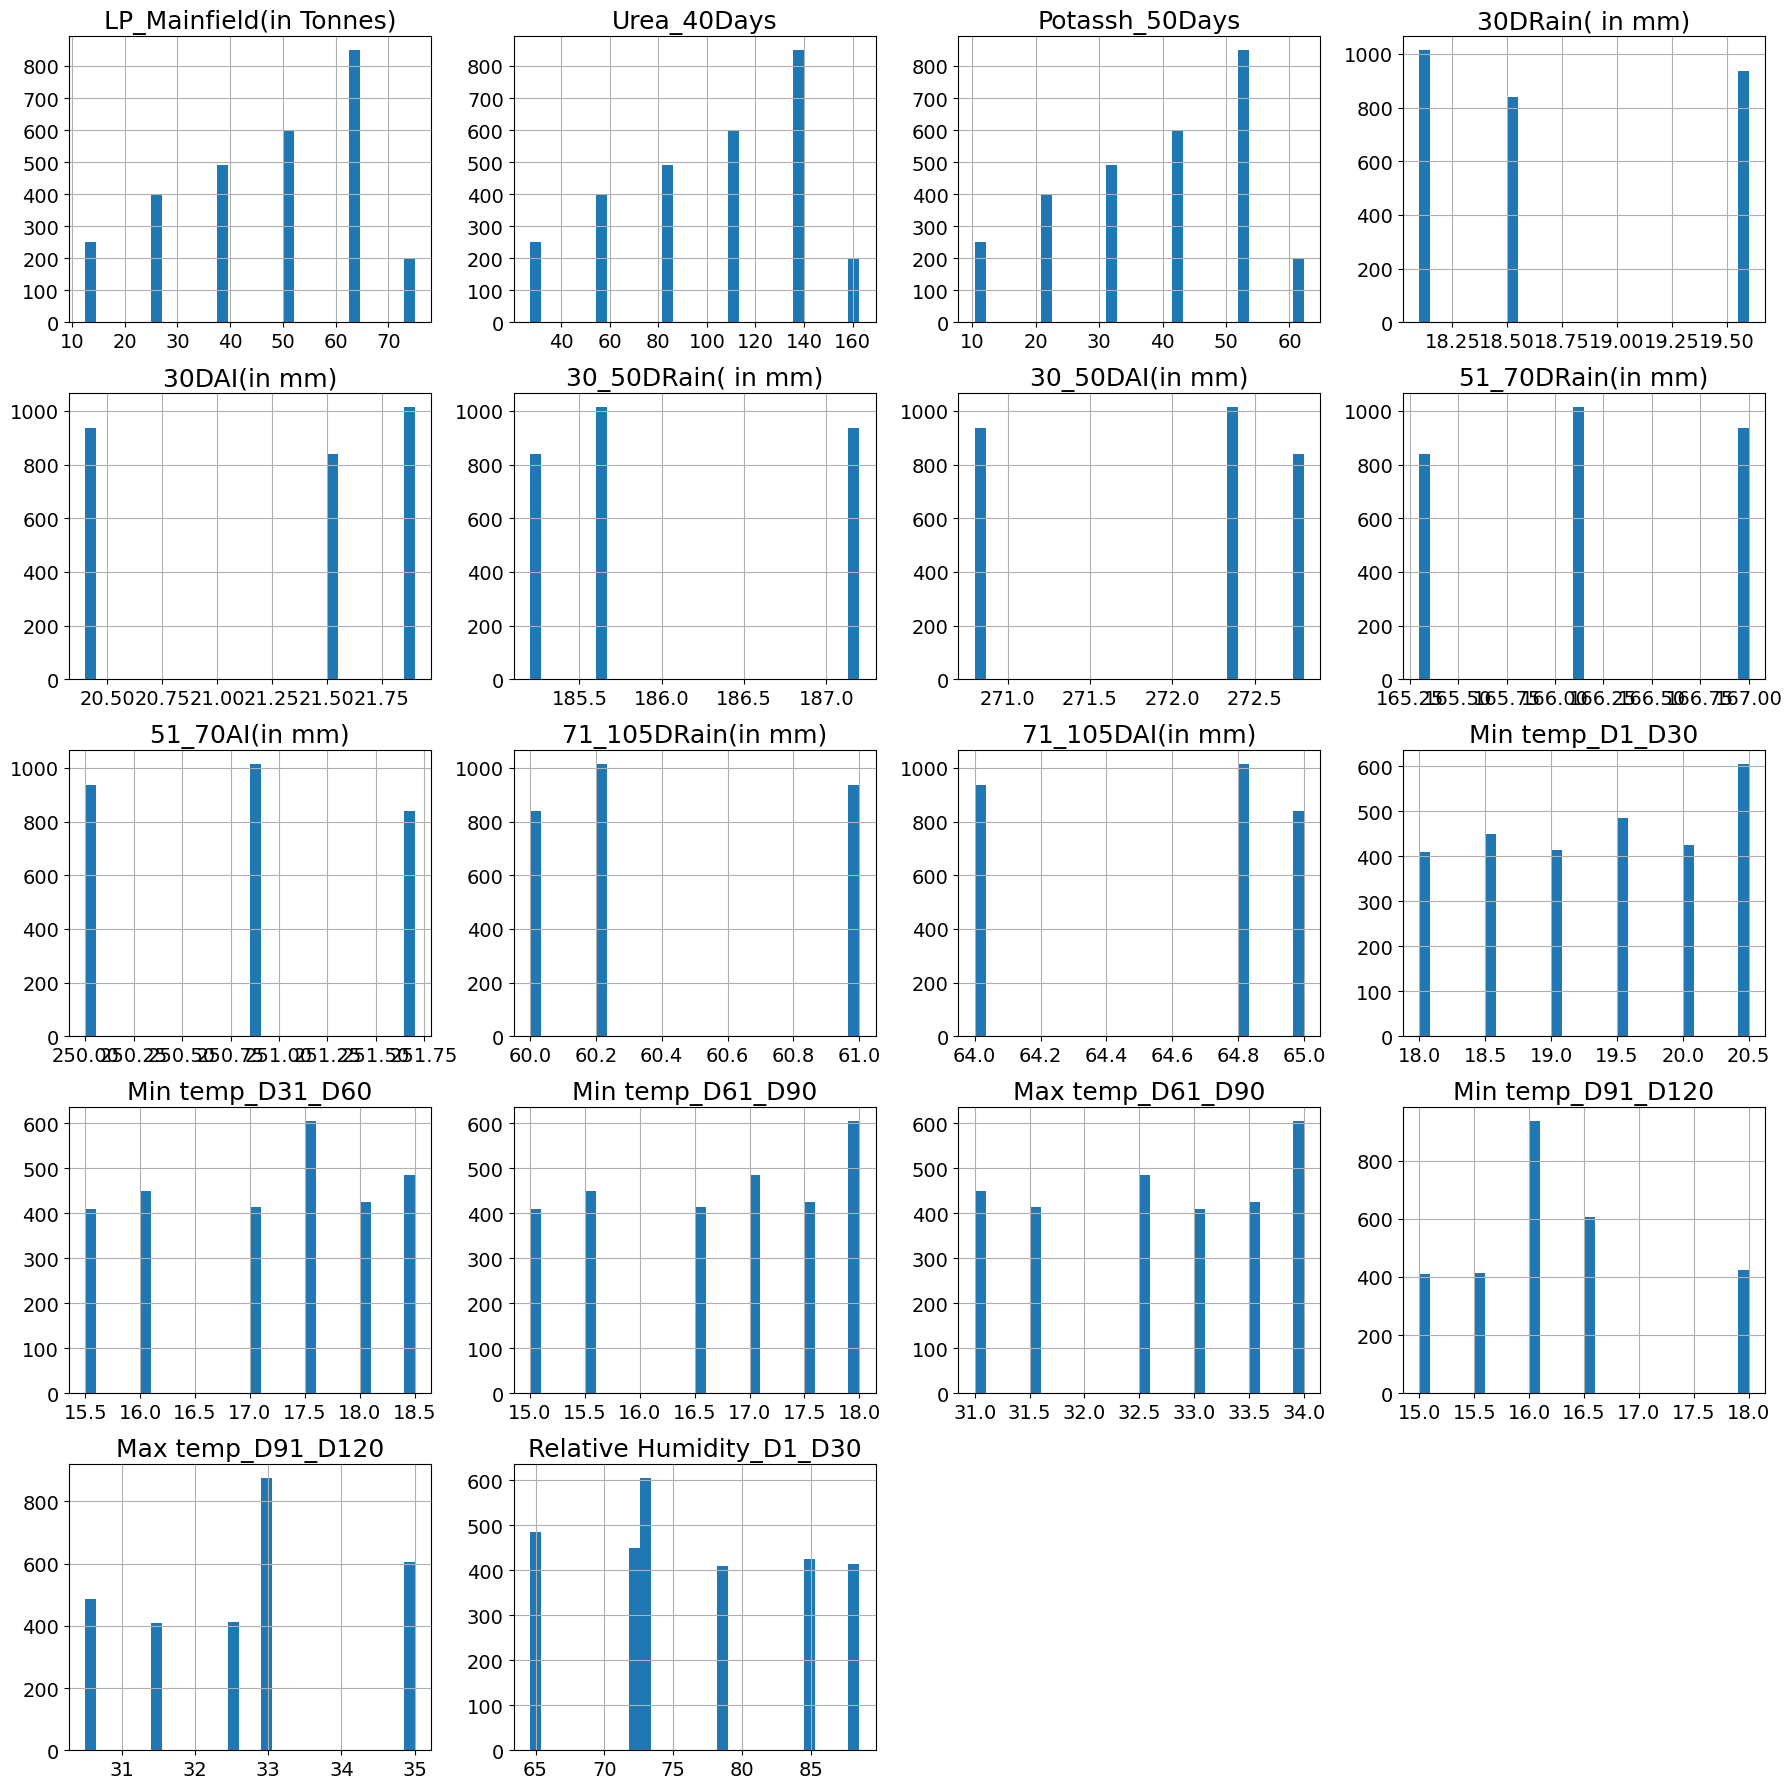

In [14]:
# Histograms for continuous features with larger subplot titles
axes = data[continuous_features].hist(figsize=(18, 18), bins=30, layout=(5, 4), xlabelsize=14, ylabelsize=14)

# adjust the title size for each individual subplot
for ax in axes.flatten():
    ax.set_title(ax.get_title(), fontsize=18)

plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Histograms_for_continuous_features.png', dpi=300, bbox_inches='tight')
plt.show()

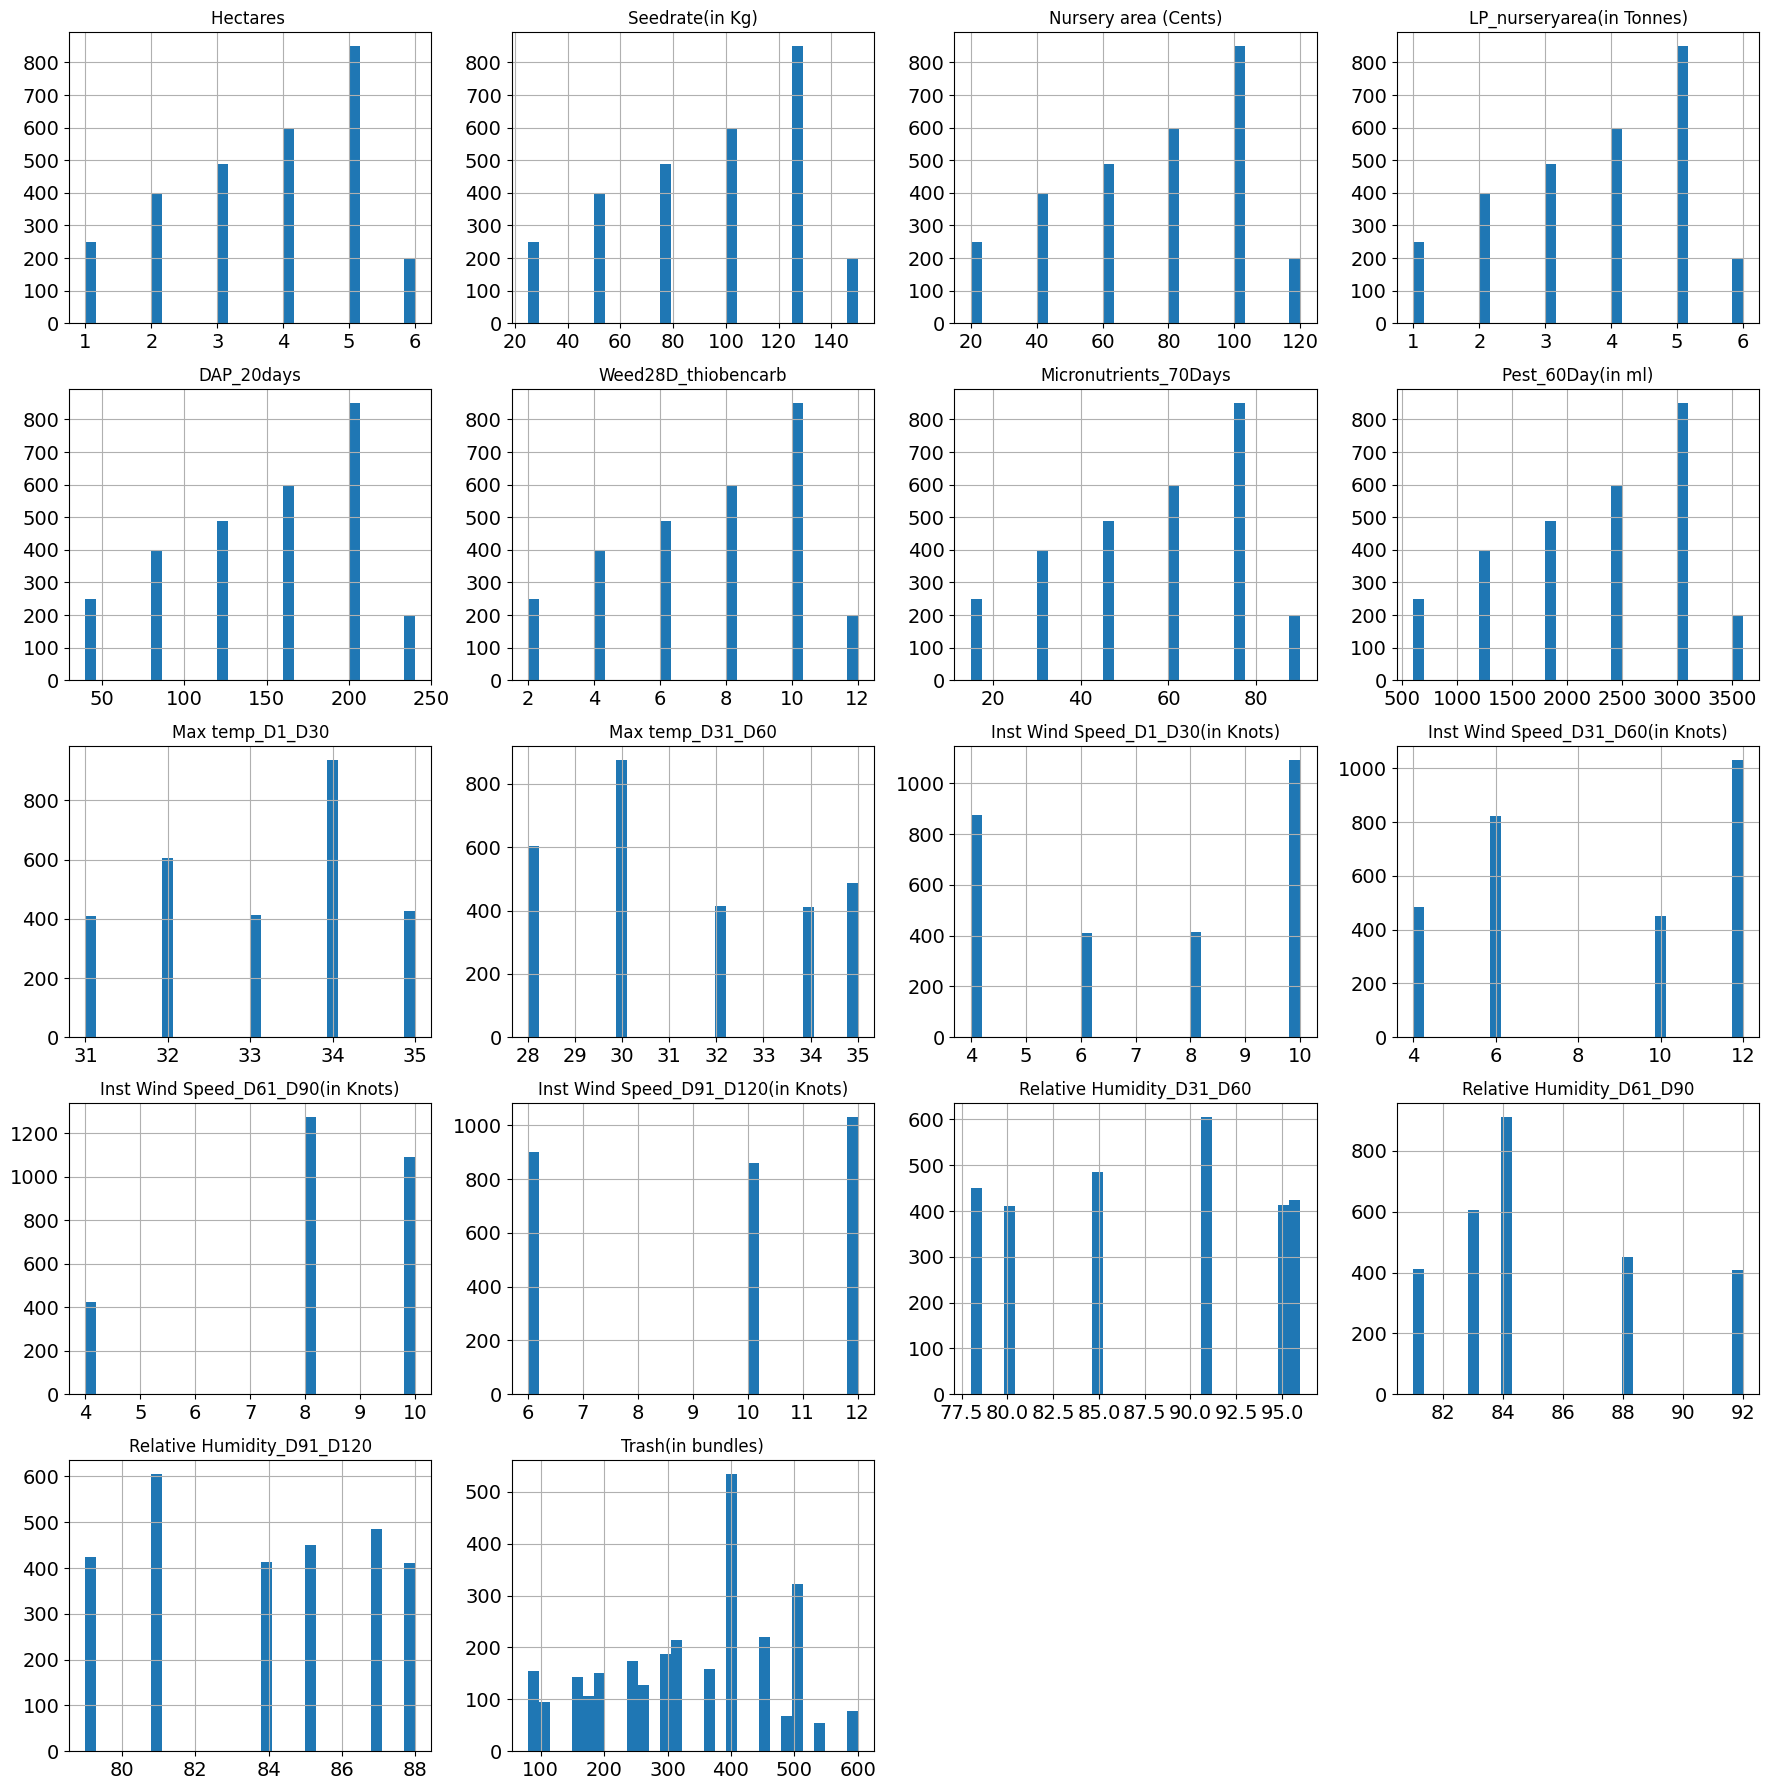

In [15]:
# Histograms for integer features
data[integer_features].hist(figsize=(18, 18), bins=30, layout=(5, 4), xlabelsize=14, ylabelsize=14)
plt.tick_params(axis='both', labelsize=14)
# adjust the title size for each individual subplot
for ax in axes.flatten():
    ax.set_title(ax.get_title(), fontsize=18)

plt.tight_layout()
# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Histograms_for_integer_features.png', dpi=300, bbox_inches='tight')
plt.show()

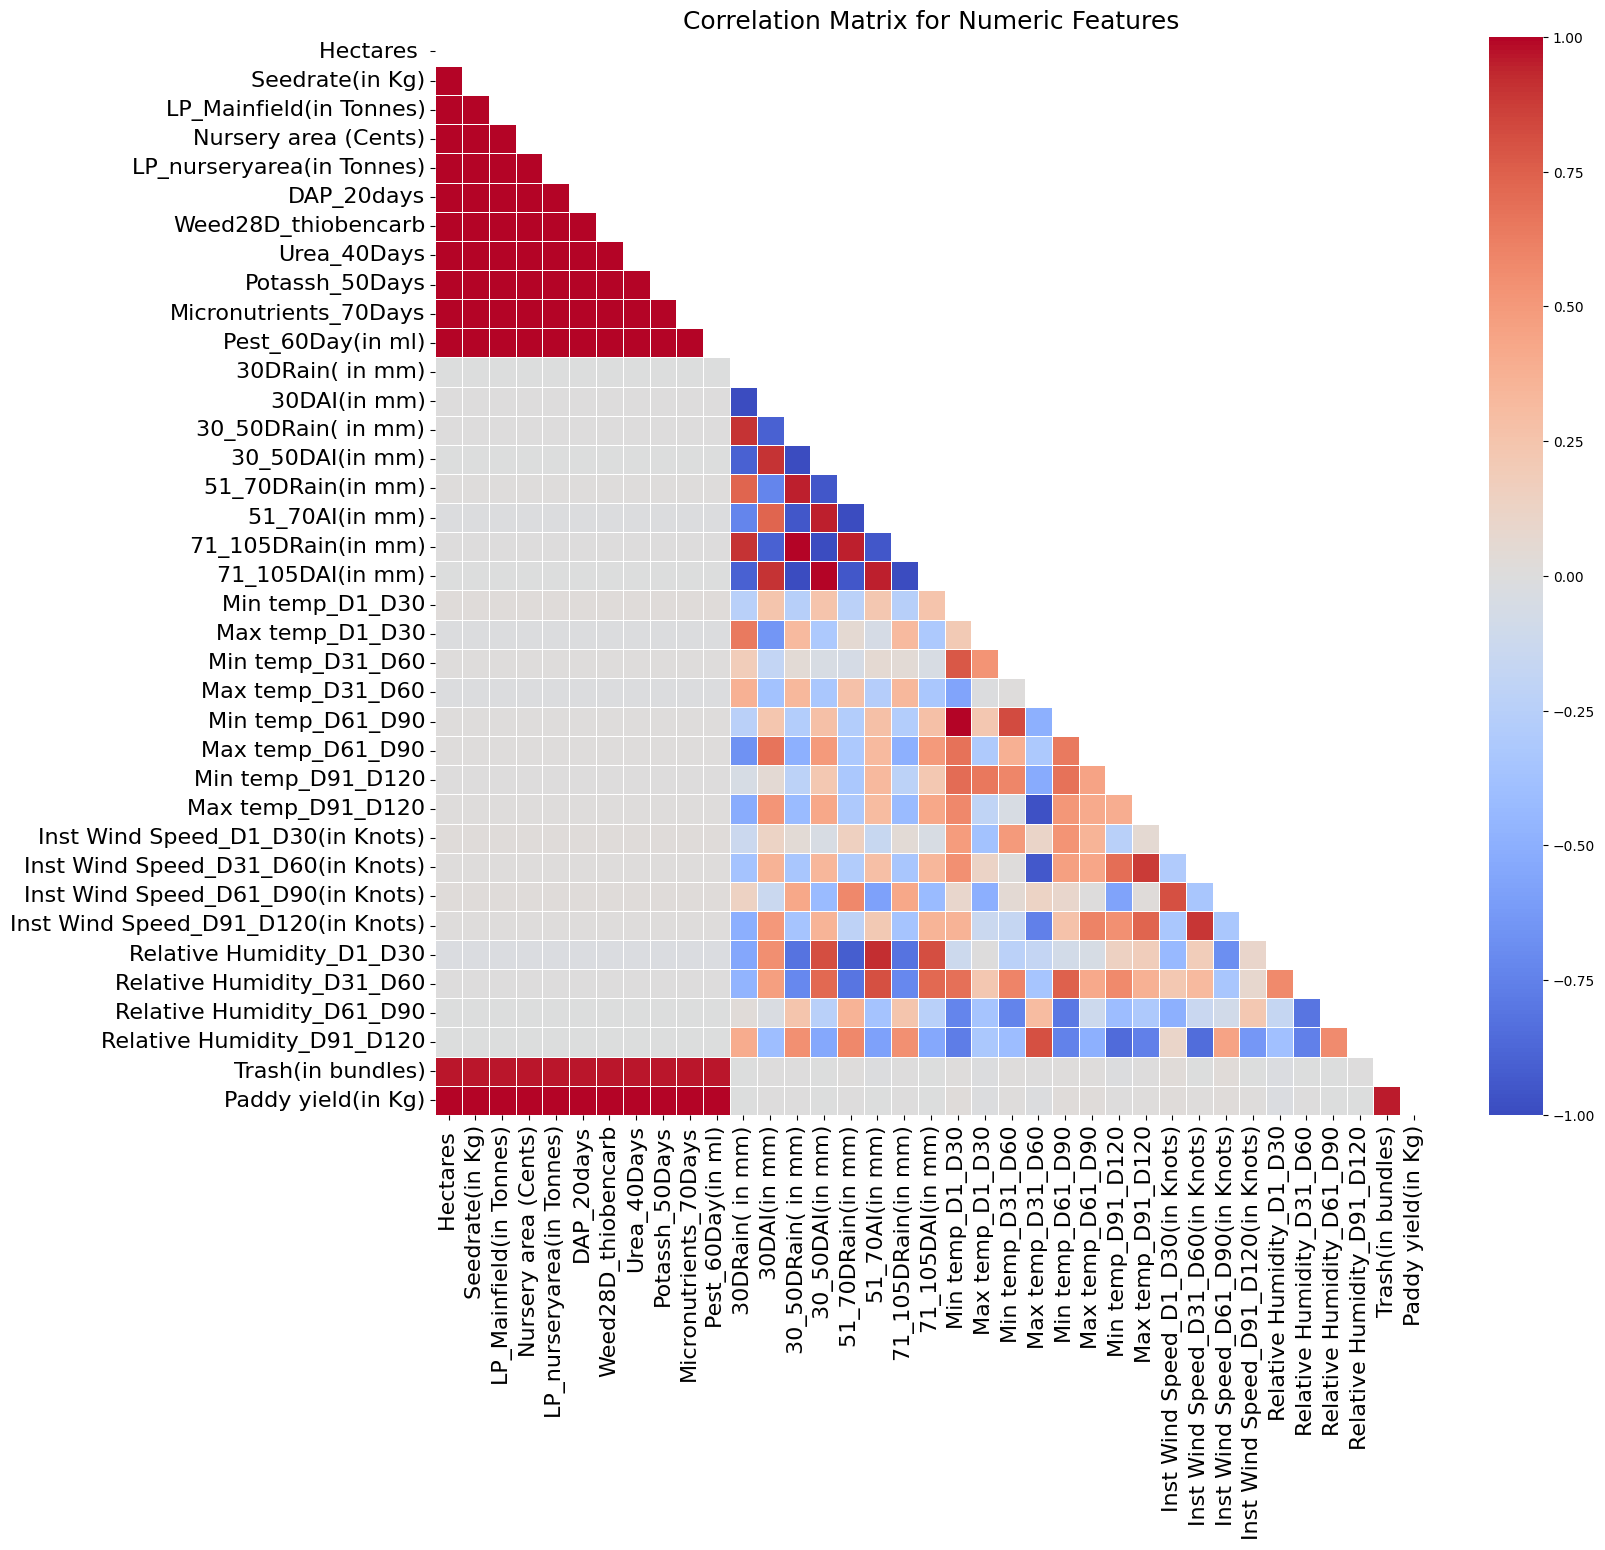

0


In [16]:
# Correlation matrix for Numerical Features
plt.figure(figsize=(16,14))
cor = data[numerical_features].corr()
mask = np.triu(np.ones_like(cor, dtype=bool))
sns.heatmap(cor, mask=mask, cmap='coolwarm', annot=False, fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix for Numeric Features', fontsize=18)
plt.tick_params(axis='both', labelsize=16)

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Correlation_Matrix_for_Numeric_Features.png', dpi=300, bbox_inches='tight')

plt.show()
print(cor.isna().sum().sum())

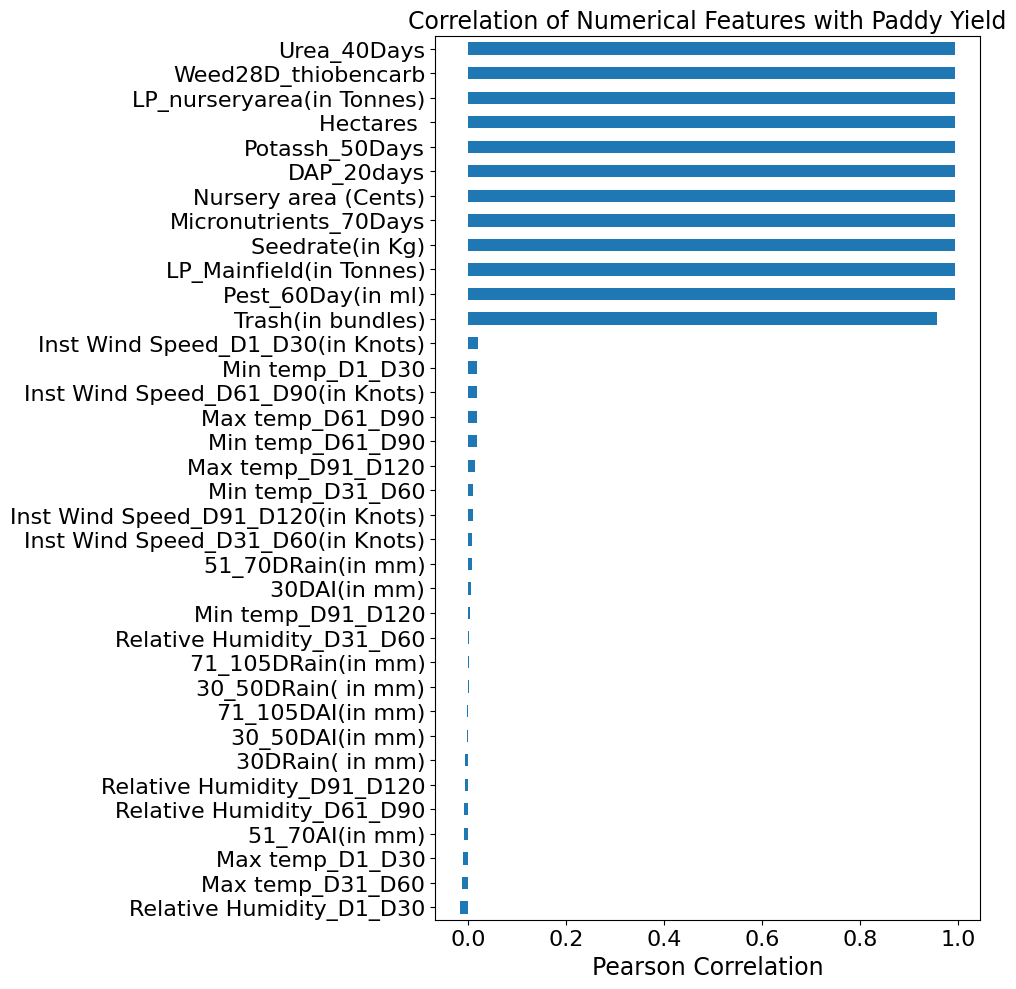

In [17]:
# Pearson Correlation of Numerical Features with Target

target_corr = (data[numerical_features].corr()[target].drop(target).sort_values())

plt.figure(figsize=(10, 10))
target_corr.plot(kind='barh')

plt.title('Correlation of Numerical Features with Paddy Yield', fontsize=17)
plt.xlabel('Pearson Correlation', fontsize=17)
plt.tick_params(axis='both', labelsize=16)
plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Pearson_Correlation.png', dpi=300, bbox_inches='tight')

plt.show()

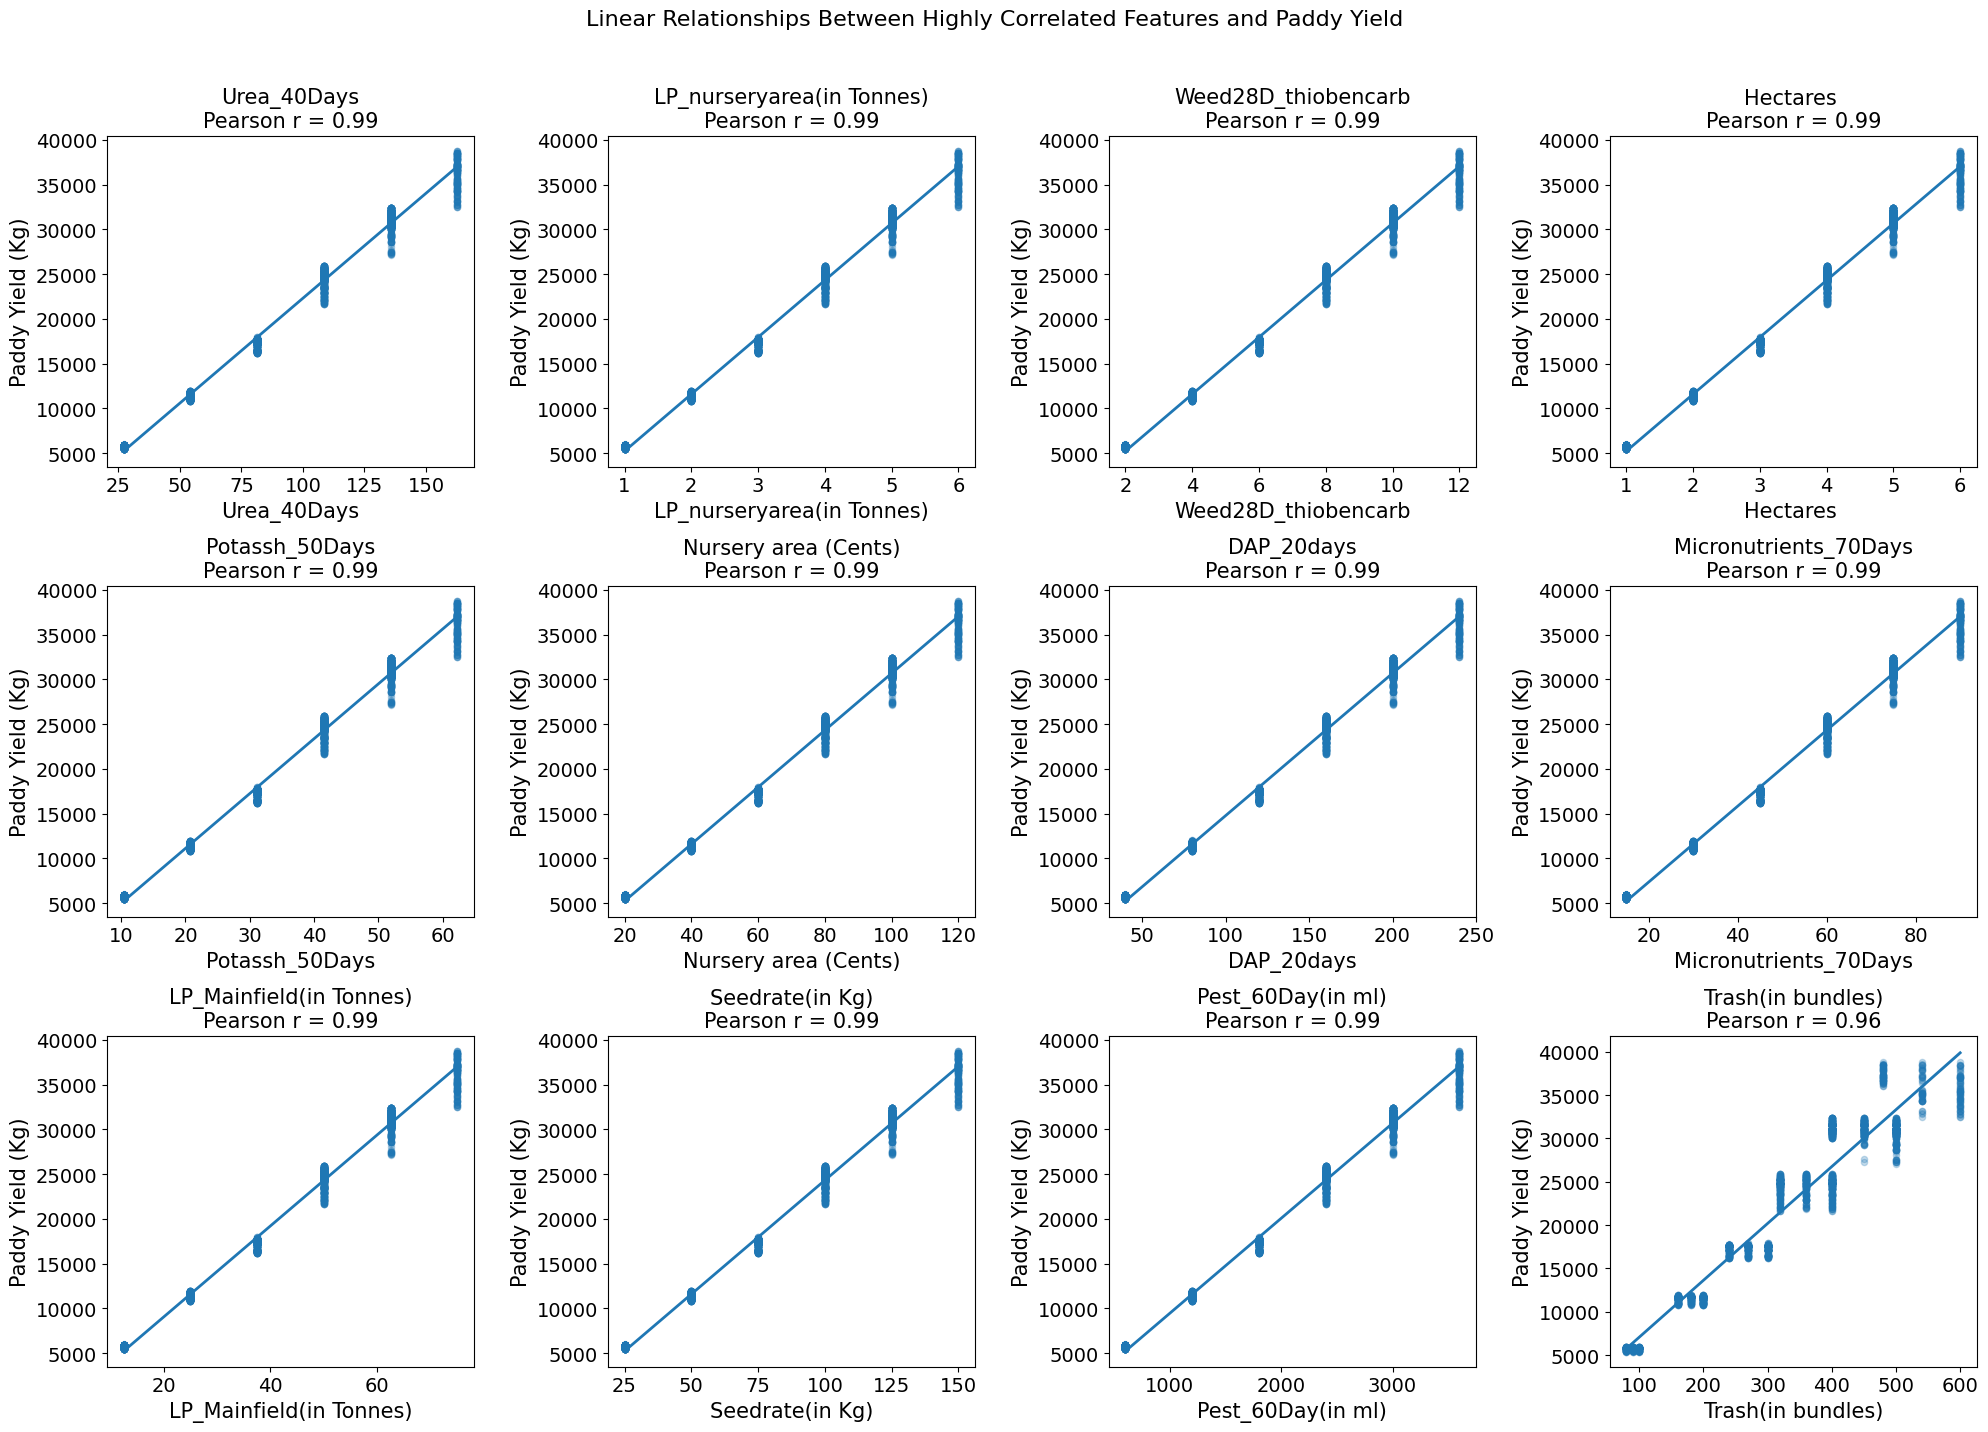

In [21]:
top_features = target_corr[target_corr.abs() >= 0.8].sort_values(ascending=False).index

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
axes = axes.flatten()

for ax, col in zip(axes, top_features):
    # regression plot
    sns.regplot(data=data, x=col, y=target, ax=ax,
        scatter_kws={'alpha': 0.25, 's': 20}, line_kws={'linewidth': 2})

    ax.set_title(f'{col}\nPearson r = {target_corr[col]:.2f}', fontsize=15)

    ax.set_xlabel(col, fontsize=15)
    ax.set_ylabel('Paddy Yield (Kg)', fontsize=15)
    ax.tick_params(axis='both', labelsize=14)

plt.suptitle('Linear Relationships Between Highly Correlated Features and Paddy Yield', fontsize=16, y=1.02)
plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Linear_Relationships_Between_Highly_Correlated_Features_and_Yield.png', dpi=300, bbox_inches='tight')


plt.show()

Several numerical features exhibit strong positive correlations with paddy yield, with a number of variables having correlations above 0.8. These include agricultural inputs such as fertilizers and nutrients (`Urea_40Days`, `Potassh_50Days`, `DAP_20days`, and `Micronutrients_70Days`), crop protection measures (`Weed28D_thiobencarb` and `Pest_60Day(in ml)`), and cultivation-related variables such as cultivated area, seed rate, and nursery area. The heatmap also shows strong correlations among these features, indicating multicollinearity. Scatterplots with fitted regression lines suggest that their relationships with paddy yield are approximately linear.


## 2.3 Categorical Features

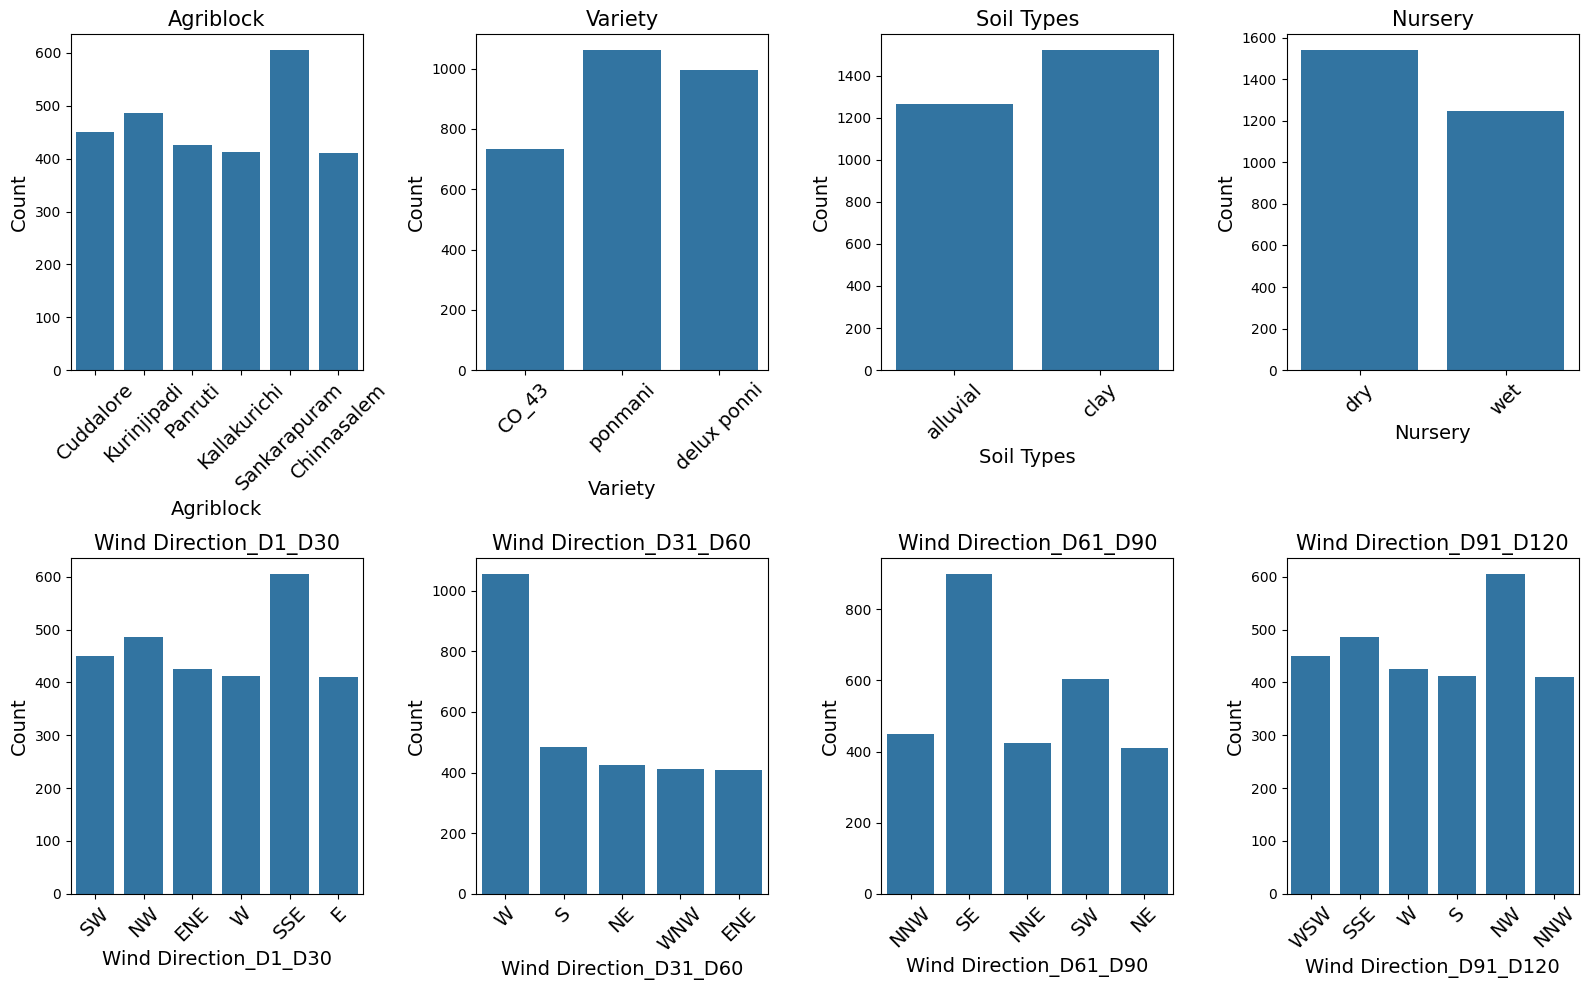

In [22]:
# Categorical feature distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 10))

axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(data=data, x=col, ax=axes[i])

    axes[i].set_title(f'{col}', fontsize=15)
    axes[i].set_xlabel(col, fontsize=14)
    axes[i].set_ylabel('Count', fontsize=14)
    axes[i].tick_params(axis='x', rotation=45, labelsize=14)

plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Categorical_feature_distributions.png', dpi=300, bbox_inches='tight')

plt.show()

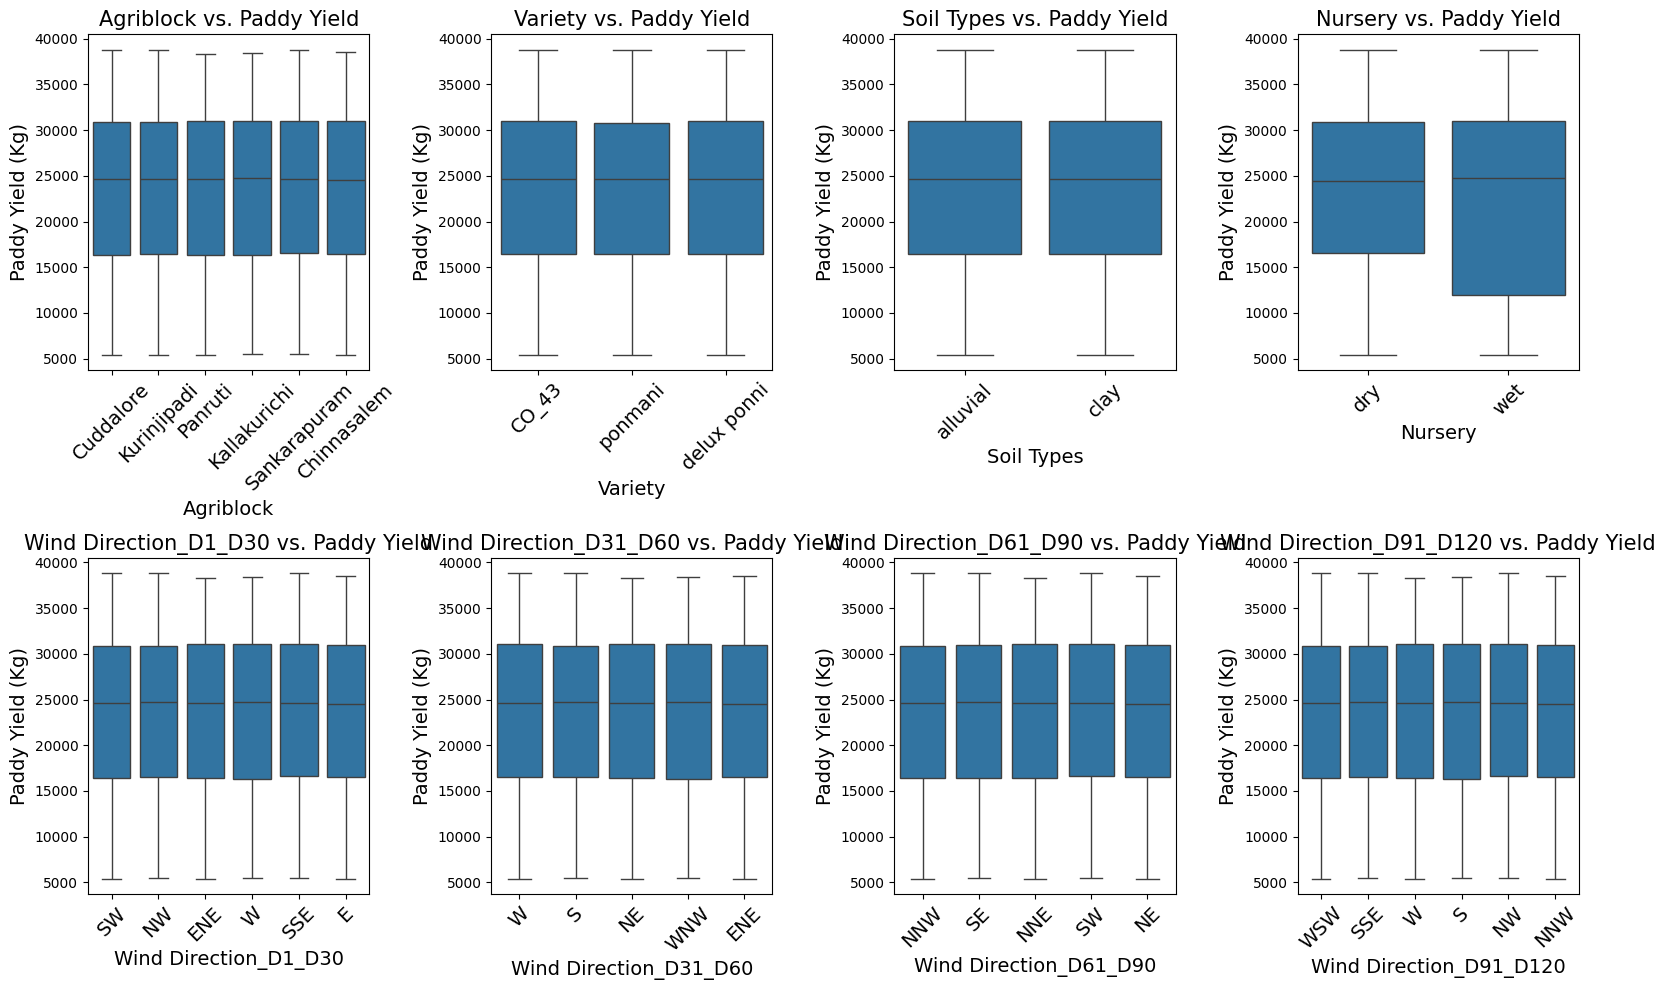

In [23]:
# Categorical Features vs. Paddy Yield
fig, axes = plt.subplots(2, 4, figsize=(16, 10))

axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.boxplot(data=data, x=col, y=target, ax=axes[i])

    axes[i].set_title(f'{col} vs. Paddy Yield', fontsize=15)
    axes[i].set_xlabel(col, fontsize=14)
    axes[i].set_ylabel('Paddy Yield (Kg)', fontsize=14)
    axes[i].tick_params(axis='x', rotation=45, labelsize=14)

plt.tight_layout()
# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'Categorical_feature_vs_Yield.png', dpi=300, bbox_inches='tight')

plt.show()

We see that there is no apparent pattern that can distinguish the target variable based on the categorical features. Hence, the wave-like distribution of the target variable may not caused by the categorical variables.

## 2.4 Data Information

In conclusion, the EDA shows that paddy yield has a wave-like distribution, while categorical features do not appear to explain this pattern. Several numerical features have strong positive relationships with yield and are also highly correlated with each other, indicating multicollinearity. The approximately linear relationships observed in the scatterplots suggest that linear models may perform well, while PCA and Lasso can help address the redundancy among predictors.


# 3. Dimensionality Reduction

## 3.1 Data Preprocessing

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate features and target
X = data.drop(columns=[target])
y = data[target]

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'int32', 'float64', 'float32']).columns.tolist()

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing
# Numerical feature are standardized
# Categorical variables are converted into dummy variables.
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), numerical_features),
                  ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)]
)

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (2231, 71)
Testing data shape: (558, 71)


# 3.2 Principal Compoent Analysis (PCA)

The EDA revealed substantial multicollinearity among several features. Therefore, PCA was applied to transform the correlated features into a smaller set of orthogonal principal components while retaining most of the information in the original feature space.

In [25]:
from sklearn.decomposition import PCA

# Fit PCA on the training data
pca = PCA()
X_train_pca = pca.fit_transform(X_train_processed)

# Transform the test data
X_test_pca = pca.transform(X_test_processed)

print("Original number of features:", X_train_processed.shape[1])
print("Number of principal components:", X_train_pca.shape[1])

Original number of features: 71
Number of principal components: 71


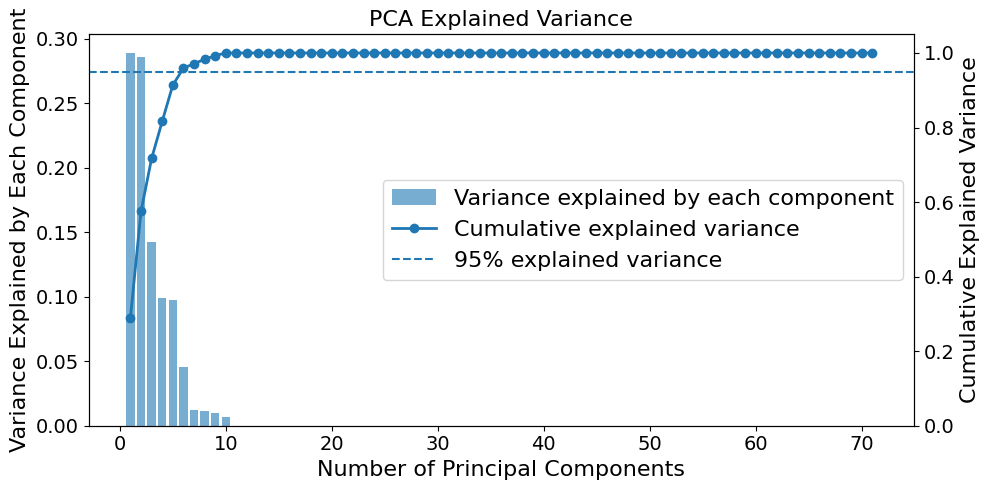

In [29]:
# Visualization:
# Cumulative Explained Variance
# Variance Explained by Each Component
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

components = range(1, len(explained_variance) + 1)

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bars: variance explained by each component
bars = ax1.bar(components, explained_variance,
    alpha=0.6, label="Variance explained by each component")

ax1.set_xlabel("Number of Principal Components", fontsize=16)
ax1.set_ylabel("Variance Explained by Each Component", fontsize=16)
ax1.tick_params(axis='both', labelsize=14)

# Line: cumulative variance
ax2 = ax1.twinx()

line = ax2.plot(components, cumulative_variance,
    marker='o', linewidth=2, label="Cumulative explained variance")

threshold = ax2.axhline(y=0.95, linestyle='--', label="95% explained variance")

ax2.set_ylabel("Cumulative Explained Variance", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis='both', labelsize=14)

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(handles1 + handles2, labels1 + labels2,loc="center right", fontsize=16)

plt.title("PCA Explained Variance", fontsize=16)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'PCA.png', dpi=300, bbox_inches='tight')

plt.show()

In [30]:
# Choosing the number of components
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components explaining at least 95% variance:", n_components)

Number of components explaining at least 95% variance: 6


In [31]:
# refit PCA with that number
pca_final = PCA(n_components=n_components)

X_train_pca = pca_final.fit_transform(X_train_processed)
X_test_pca = pca_final.transform(X_test_processed)

print("Original number of features:", X_train_processed.shape[1])
print("Reduced number of features:", X_train_pca.shape[1])

Original number of features: 71
Reduced number of features: 6


# 4. Predictions

## 4.1. Linear Regression

### 4.1.1. Linear Regression - Without PCA

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

lr = LinearRegression()

start = time.perf_counter()
lr.fit(X_train_processed, y_train)
lr_train_time = time.perf_counter() - start

y_pred_lr = lr.predict(X_test_processed)

print("Linear Regression (Without PCA)")
print("Training Time:", np.round(lr_train_time, 4), "seconds")
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_lr)),4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_lr),4))
print("R²:", np.round(r2_score(y_test, y_pred_lr),4))

Linear Regression (Without PCA)
Training Time: 0.0237 seconds
RMSE: 927.936
MAE: 698.3192
R²: 0.9894


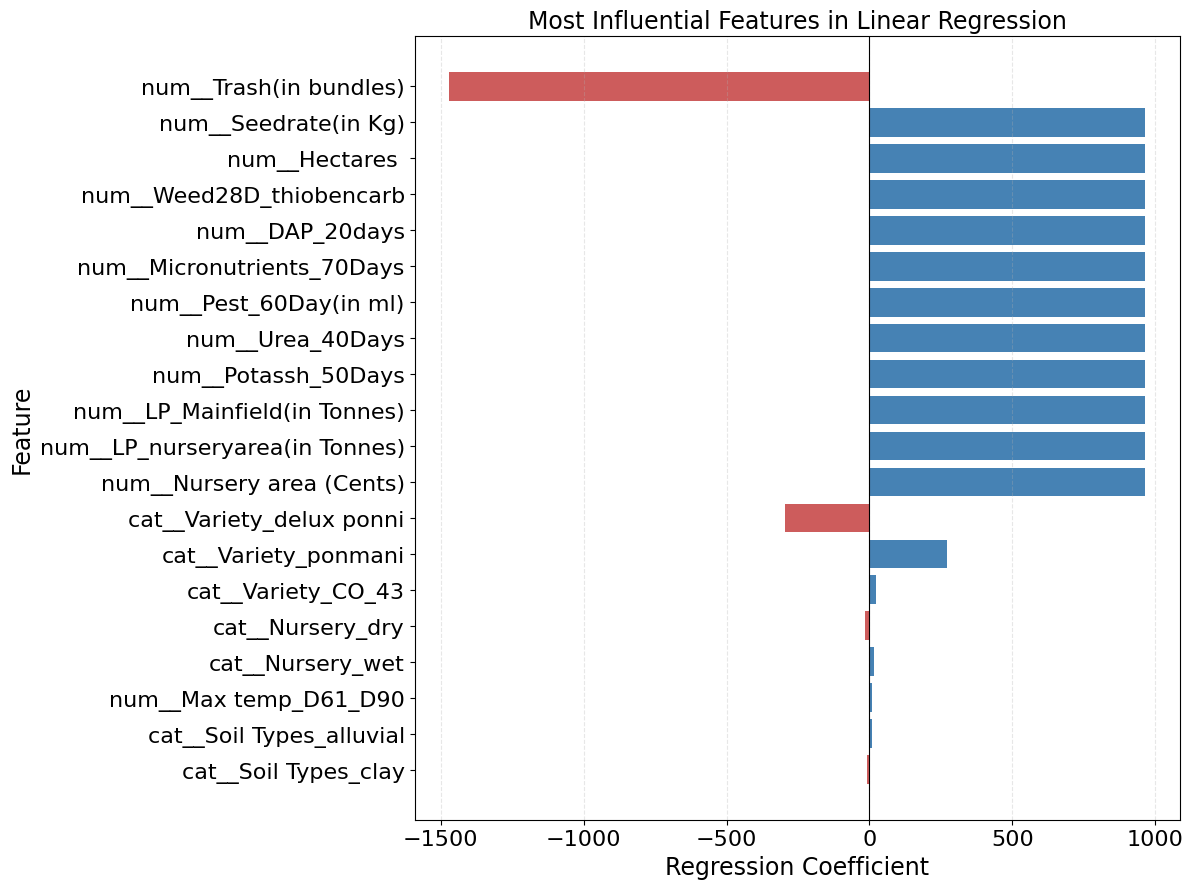

In [34]:
# coefficient plot

feature_names = preprocessor.get_feature_names_out()

lr_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr.coef_})

lr_importance["Abs_Coefficient"] = lr_importance["Coefficient"].abs()
lr_importance = lr_importance.sort_values("Abs_Coefficient", ascending=False)

# print(lr_importance.to_string(index=False))



# Select top 20 features by absolute coefficient
top_20 = lr_importance.head(20).sort_values("Abs_Coefficient")

# Color positive and negative coefficients differently
colors = ["steelblue" if coef >= 0 else "indianred"
    for coef in top_20["Coefficient"]]

plt.figure(figsize=(12, 9))
plt.barh(top_20["Feature"], top_20["Coefficient"], color=colors)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Regression Coefficient", fontsize=17)
plt.ylabel("Feature", fontsize=17)
plt.tick_params(axis='both', labelsize=16)
plt.title("Most Influential Features in Linear Regression", fontsize=17)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'linear_regression_coefficient.png', dpi=300, bbox_inches='tight')

plt.show()



### 4.1.2. Linear Regression - With PCA

In [35]:
lr_pca = LinearRegression()

start = time.perf_counter()
lr_pca.fit(X_train_pca, y_train)
lr_pca_train_time = time.perf_counter() - start


y_pred_lr_pca = lr_pca.predict(X_test_pca)

print("Linear Regression (With PCA)")
print("Training Time:", np.round(lr_pca_train_time, 4), "seconds")
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_lr_pca)),4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_lr_pca),4))
print("R²:", np.round(r2_score(y_test, y_pred_lr_pca),4))

Linear Regression (With PCA)
Training Time: 0.0085 seconds
RMSE: 1004.9139
MAE: 747.831
R²: 0.9875


## 4.2. Lasso Regression

### 4.2.1. Lasso Regression - Without PCA

In [36]:
from sklearn.linear_model import LassoCV

# Lasso regularization and cross-validation to select the best regularization parameter.
lasso = LassoCV(cv=5, max_iter=20000, random_state=42)

start = time.perf_counter()
lasso.fit(X_train_processed, y_train)
lasso_train_time = time.perf_counter() - start

y_pred_lasso = lasso.predict(X_test_processed)

print("Lasso Regression (Without PCA)")
print("Training Time:", np.round(lasso_train_time, 4), "seconds")
print("Best alpha:", np.round(lasso.alpha_,4))
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_lasso)),4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_lasso),4))
print("R²:", np.round(r2_score(y_test, y_pred_lasso),4))
# print("Number of nonzero coefficients:", np.sum(lasso.coef_ >= 1e-10))

# Get selected features
feature_names = preprocessor.get_feature_names_out()
selected_mask = np.abs(lasso.coef_) > 1e-10

# Create DataFrame with feature names and coefficients
selected_features_df = pd.DataFrame({"Feature": feature_names[selected_mask],
                                     "Coefficient": lasso.coef_[selected_mask]})

# Sort by absolute coefficient magnitude
selected_features_df["Abs_Coefficient"] = selected_features_df["Coefficient"].abs()
selected_features_df = selected_features_df.sort_values(by="Abs_Coefficient", ascending=False
                            ).drop(columns="Abs_Coefficient").reset_index(drop=True)
print("Number of selected features:", len(selected_features_df))
display(selected_features_df)


Lasso Regression (Without PCA)
Training Time: 0.8268 seconds
Best alpha: 10.5729
RMSE: 941.0506
MAE: 706.5258
R²: 0.9891
Number of selected features: 6


,Feature,Coefficient
0,num__Hectares,9185.515798
1,cat__Variety_ponmani,-130.057908
2,cat__Variety_delux ponni,56.155450
3,num__Max temp_D61_D90,21.412487
4,num__Inst Wind Speed_D1_D30(in Knots),5.305761
5,num__Max temp_D1_D30,-1.515412


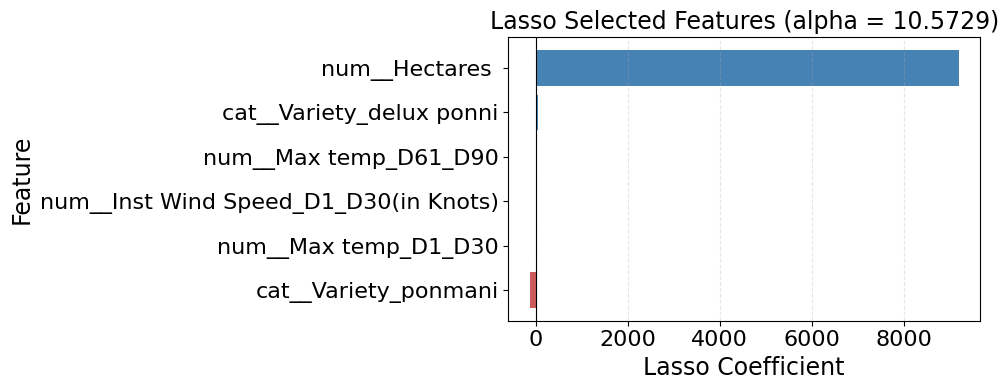

In [37]:
# coefficient plot

# Sort by coefficient for a horizontal bar chart
plot_df = selected_features_df.sort_values("Coefficient")

# Use different colors for positive and negative coefficients
colors = ["steelblue" if coef >= 0 else "indianred"
          for coef in plot_df["Coefficient"]]

plt.figure(figsize=(10, max(4, 0.45 * len(plot_df))))

plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Lasso Coefficient", fontsize=17)
plt.ylabel("Feature", fontsize=17)
plt.tick_params(axis='both', labelsize=16)
plt.title(f"Lasso Selected Features (alpha = {lasso.alpha_:.4f})", fontsize=17)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'lasso_feature_selection.png', dpi=300, bbox_inches='tight')

plt.show()


Hectares is expected to have a strong relationship with total yield because a larger cultivated area can produce more rice.

### 4.2.2. Lasso Regression - With PCA

In [38]:
# Lasso regularization and cross-validation to select the best regularization parameter.
lasso_pca = LassoCV(cv=5, max_iter=20000, random_state=42)

start = time.perf_counter()
lasso_pca.fit(X_train_pca, y_train)
lasso_pca_train_time = time.perf_counter() - start


y_pred_lasso_pca = lasso_pca.predict(X_test_pca)

print("Lasso Regression (With PCA)")
print("Training Time:", np.round(lasso_pca_train_time, 4), "seconds")
print("Best alpha:", np.round(lasso_pca.alpha_,4))
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_lasso_pca)),4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_lasso_pca),4))
print("R²:", np.round(r2_score(y_test, y_pred_lasso_pca),4))
print("Number of nonzero coefficients:", np.sum(lasso_pca.coef_ >= 1e-10))

Lasso Regression (With PCA)
Training Time: 0.1197 seconds
Best alpha: 24.8591
RMSE: 1006.953
MAE: 750.158
R²: 0.9875
Number of nonzero coefficients: 1


## 4.3 Random Forest Regression

### 4.3.1. Random Forest Regression - Without PCA

In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)

start = time.perf_counter()
rf.fit(X_train_processed, y_train)
rf_train_time = time.perf_counter() - start

y_pred_rf = rf.predict(X_test_processed)

print("Random Forest (Without PCA)")
print("Training Time:", np.round(rf_train_time, 4), "seconds")
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_rf), 4))
print("R²:", np.round(r2_score(y_test, y_pred_rf), 4))

Random Forest (Without PCA)
Training Time: 3.2667 seconds
RMSE: 886.8067
MAE: 632.583
R²: 0.9903


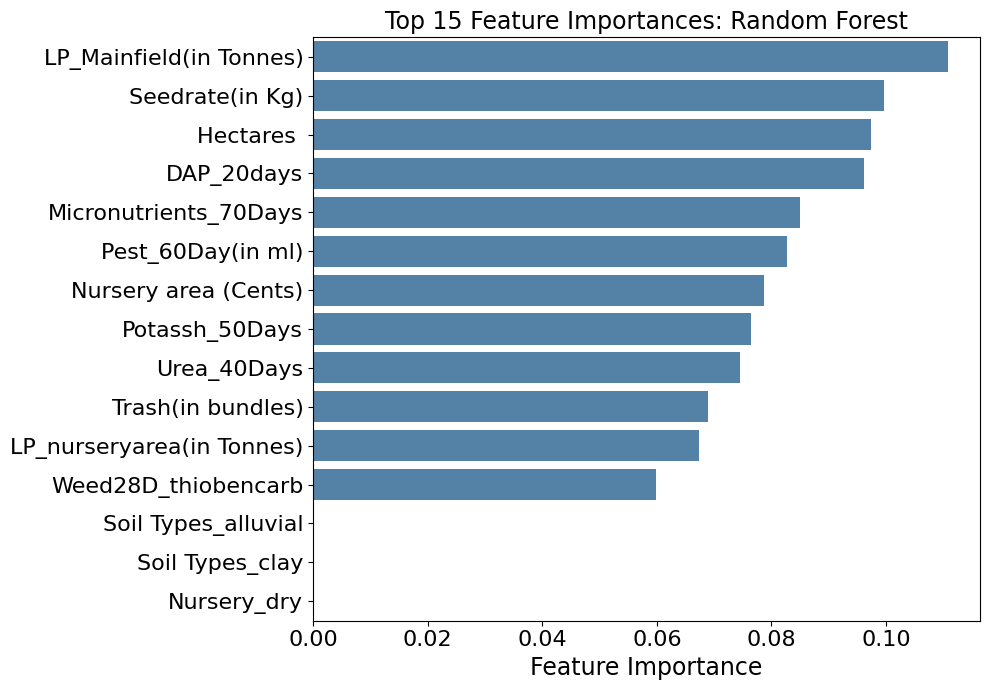

In [40]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create feature importance table
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

# Clean preprocessing prefixes for readability
rf_importance['Feature'] = (
    rf_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

# Plot top 15 features
top_importance = rf_importance.sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_importance, x='Importance', y='Feature', color='steelblue')
plt.title('Top 15 Feature Importances: Random Forest', fontsize=17)
plt.xlabel('Feature Importance', fontsize=17)
plt.ylabel('', fontsize=17)
plt.tick_params(axis='both', labelsize=16)
plt.tight_layout()

# save graph path
graphics_path = '/content/drive/MyDrive/UIUC/IE 498 - Machine Learning in Finance/Project/project_graphics/'
plt.savefig(graphics_path + 'random_forest_feature_importances.png', dpi=300, bbox_inches='tight')

plt.show()

### 4.3.2. Random Forest Regression - With PCA

In [ ]:
rf_pca = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)

start = time.perf_counter()
rf_pca.fit(X_train_pca, y_train)
rf_pca_train_time = time.perf_counter() - start

y_pred_rf_pca = rf_pca.predict(X_test_pca)

print("Random Forest (With PCA)")
print("Training Time:", np.round(rf_pca_train_time, 4), "seconds")
print("RMSE:", np.round(np.sqrt(mean_squared_error(y_test, y_pred_rf_pca)), 4))
print("MAE:", np.round(mean_absolute_error(y_test, y_pred_rf_pca), 4))
print("R²:", np.round(r2_score(y_test, y_pred_rf_pca), 4))

Random Forest (With PCA)
Training Time: 2.5112 seconds
RMSE: 887.6489
MAE: 633.5083
R²: 0.9903


## 4.4. Support Vector Regression

In [ ]:
# use GridSearchCV to tune hyperparameters of SVR
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV


# Hyperparameter grid
param_grid = {
    'regressor__svr__C': [1, 10, 100],
    'regressor__svr__epsilon': [0.01, 0.1, 0.5],
    'regressor__svr__gamma': ['scale', 0.01, 0.1]
}

# Function to tune and evaluate SVR
def evaluate_svr(X_train, X_test, y_train, y_test, model_name):

    svr_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR(kernel='rbf'))
    ])

    svr_model = TransformedTargetRegressor(regressor=svr_pipeline, transformer=StandardScaler())

    grid_search = GridSearchCV(svr_model, param_grid,
                               cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

    start = time.perf_counter()
    grid_search.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    best_svr = grid_search.best_estimator_
    y_pred = best_svr.predict(X_test)

    print(f"\n{model_name}")
    print("Best parameters:", grid_search.best_params_)
    print("Best CV RMSE:", round(-grid_search.best_score_, 4))
    print("Training Time:", round(train_time, 4), "seconds")
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
    print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
    print("R²:", round(r2_score(y_test, y_pred), 4))

    return best_svr, y_pred, train_time






### 4.4.1. Support Vector Regression - Without PCA

In [ ]:
# SVR without PCA
best_svr, y_pred_svr, svr_train_time = evaluate_svr(X_train_processed, X_test_processed,
    y_train, y_test, "SVR (Without PCA)")



SVR (Without PCA)
Best parameters: {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.01, 'regressor__svr__gamma': 0.01}
Best CV RMSE: 842.8851
Training Time: 113.3135 seconds
RMSE: 870.3701
MAE: 611.7301
R²: 0.9907


### 4.4.2. Support Vector Regression - With PCA

In [ ]:
# SVR with PCA
best_svr_pca, y_pred_svr_pca, svr_pca_train_time = evaluate_svr(X_train_pca, X_test_pca,
    y_train, y_test, "SVR (With PCA)")



SVR (With PCA)
Best parameters: {'regressor__svr__C': 100, 'regressor__svr__epsilon': 0.01, 'regressor__svr__gamma': 0.1}
Best CV RMSE: 873.4547
Training Time: 27.1159 seconds
RMSE: 882.2195
MAE: 595.4466
R²: 0.9904


## 4.4 Model Comparison



In [ ]:
results = []

predictions = {
    'Linear Regression (Without PCA)': (y_pred_lr, lr_train_time),
    'Linear Regression (With PCA)': (y_pred_lr_pca, lr_pca_train_time),
    'Lasso (Without PCA)': (y_pred_lasso, lasso_train_time),
    'Lasso (With PCA)': (y_pred_lasso_pca, lasso_pca_train_time),
    'SVR (Without PCA)': (y_pred_svr, svr_train_time),
    'SVR (With PCA)': (y_pred_svr_pca, svr_pca_train_time),
    'Random Forest (Without PCA)': (y_pred_rf, rf_train_time),
    'Random Forest (With PCA)': (y_pred_rf_pca, rf_pca_train_time)
}

for model_name, (y_pred, train_time) in predictions.items():
    results.append({
        'Model': model_name,
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'MAE': mean_absolute_error(y_test, y_pred),
        'R²': r2_score(y_test, y_pred),
        'Training Time (s)': train_time,
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('RMSE').reset_index(drop=True)

results_df.round(4)

,Model,RMSE,MAE,R²,Training Time (s)
0,SVR (Without PCA),870.3701,611.7301,0.9907,113.3135
1,SVR (With PCA),882.2195,595.4466,0.9904,27.1159
2,Random Forest (Without PCA),886.8067,632.5830,0.9903,2.8526
3,Random Forest (With PCA),887.6489,633.5083,0.9903,2.5112
4,Linear Regression (Without PCA),927.9360,698.3192,0.9894,0.0179
5,Lasso (Without PCA),941.0506,706.5258,0.9891,0.1933
6,Linear Regression (With PCA),1004.9139,747.8310,0.9875,0.0048
7,Lasso (With PCA),1006.9530,750.1580,0.9875,0.0754


All models achieve high R² values (0.9875–0.9907), indicating that they explain over 98% of the variation in paddy yield. SVR without PCA performs best, with the lowest RMSE (870.3701) and highest R² (0.9907).




# 4. Concluding Remarks

The results show that PCA does not improve predictive performance in our experiments. All four models achieve slightly better results without PCA, although the difference is small for Random Forest.

PCA reduces the dimensionality of the feature space and may improve computational efficiency, but it can also discard information relevant to predicting paddy yield because it prioritizes variance in the predictors rather than predictive relevance to the target.

Furthermore, PCA transforms the original variables into principal components, making the results less directly interpretable. Since our project aims not only to predict paddy yield but also to investigate the factors associated with productivity, we prioritize models without PCA and retain PCA-based models for comparison. PCA may be more useful when dimensionality reduction or computational efficiency is a primary concern and predictive performance remains acceptable.


# 5. References

### Dataset Source

This project uses the **Paddy Dataset** from the UCI Machine Learning Repository.

**Source:** Subramaniyan, M. (2023). Paddy Dataset. UCI Machine Learning Repository. (https://doi.org/10.24432/C55W3J).

**License:** CC BY-SA 4.0